# Parte 5 — Modelagem com scikit-learn

**Objetivo desta parte:** conhecer o **scikit-learn** (`sklearn`), o pacote de machine
learning mais usado em Python, percorrendo as quatro etapas de um projeto de
modelagem:

1. **Engenharia de features** — preparar as colunas que o modelo vai usar;
2. **Treino e teste** — separar os dados para aprender e para conferir;
3. **Modelo** — treinar e fazer previsões;
4. **Avaliação** — medir o quanto o modelo acerta.

Como pano de fundo, vamos responder uma pergunta: **dá para saber se um dia foi
chuvoso olhando só para a temperatura, a umidade e o vento?**

Isso é um problema de **classificação**: a resposta é uma **categoria**
(`chuvoso` ou `seco`), e não um número.

> 🎯 **Esta é uma aula de Python.** O foco é aprender a **usar** o pacote: o que
> importar, quais funções chamar e como ler o resultado. Os detalhes matemáticos
> dos modelos ficam para a disciplina de machine learning.

Partimos da **visão diária** criada na Parte 3 (`data/processed/clima_diario.csv`).

## 0. Instalação e imports

Se ainda não tiver o pacote no seu ambiente virtual, rode no terminal:

```bash
pip install scikit-learn
```

⚠️ Pegadinha clássica: o nome para **instalar** é `scikit-learn`, mas o nome para
**importar** é `sklearn`.

O scikit-learn é dividido em **módulos**, um para cada etapa do trabalho. Em vez de
importar o pacote inteiro, importamos só o que vamos usar, com
`from sklearn.<módulo> import <função>`. Este é o mapa da aula:

| Etapa | Módulos do scikit-learn |
|---|---|
| 1. Engenharia de features | `sklearn.preprocessing`, `sklearn.compose` |
| 2. Treino e teste | `sklearn.model_selection` |
| 3. Modelo | `sklearn.dummy`, `sklearn.linear_model`, `sklearn.tree`, `sklearn.ensemble` |
| 4. Avaliação | `sklearn.metrics` |

Vamos importar cada coisa **na seção em que ela é usada**, para ficar claro de onde
ela vem.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid", palette="Set2")

print("Versão do scikit-learn:", sklearn.__version__)

Versão do scikit-learn: 1.8.0


## Carregando a visão diária

In [2]:
PROCESSED_DIR = Path("data/processed")

diario = pd.read_csv(PROCESSED_DIR / "clima_diario.csv", parse_dates=["data"])

print(diario.shape)
diario.head()

(155, 17)


,cidade,data,temp_media,temp_min,temp_max,umidade_media,precipitacao_total,vento_medio,categoria_temp,categoria_chuva,media_movel_3d,media_movel_7d,ranking_temp_dia,nome_exibicao,uf,regiao,indice_conforto_c
0,manaus,2025-01-01,27.391667,25.5,29.8,84.125000,11.0,5.654167,quente,chuvoso,27.391667,27.391667,1,Manaus,AM,Norte,31.5
1,manaus,2025-01-02,25.908333,24.7,27.8,86.104167,7.3,6.083333,ameno,chuvoso,26.650000,26.650000,4,Manaus,AM,Norte,25.9
2,manaus,2025-01-03,27.587500,24.9,30.2,80.916667,1.0,4.937500,quente,seco,26.962500,26.962500,2,Manaus,AM,Norte,31.6
3,manaus,2025-01-04,26.233333,24.5,28.9,86.166667,11.8,4.608333,quente,chuvoso,26.576389,26.780208,3,Manaus,AM,Norte,26.2
4,manaus,2025-01-05,25.795833,24.3,28.0,86.916667,8.8,4.100000,ameno,chuvoso,26.538889,26.583333,2,Manaus,AM,Norte,25.8


Cada linha é **um dia em uma cidade** (5 cidades × 31 dias = 155 linhas). A coluna
que queremos prever é a `categoria_chuva`, criada na Parte 3 com a regra "choveu mais
de 1 mm no dia → `chuvoso`".

Primeira coisa a olhar em um problema de classificação: **quantos exemplos temos de
cada categoria?**

In [3]:
diario["categoria_chuva"].value_counts()

categoria_chuva
chuvoso    101
seco        54
Name: count, dtype: int64

In [4]:
diario["categoria_chuva"].value_counts(normalize=True).round(2)

categoria_chuva
chuvoso    0.65
seco       0.35
Name: proportion, dtype: float64

Cerca de 2 em cada 3 dias foram chuvosos (é janeiro, verão chuvoso em boa parte do
Brasil). Guarde esse número: ele vai ser importante na avaliação.

---

# Etapa 1 — Engenharia de features

**Features** são as colunas que o modelo usa para tomar a decisão. "Engenharia de
features" é escolher, criar e transformar essas colunas para que o modelo consiga
aprender com elas.

## 1.1 Escolhendo as colunas: cuidado com a "cola"

Nem toda coluna pode ser usada. A `precipitacao_total` é justamente a coluna que
**define** se o dia foi chuvoso ou não — usá-la seria como deixar o gabarito colado
na prova. O modelo acertaria 100%, mas não teria aprendido nada útil.

O mesmo vale para colunas que não fazem sentido como informação (`data`, `uf`,
`nome_exibicao`...) ou que são outra classificação derivada (`categoria_temp`).

## 1.2 Criando features novas com pandas

Boa parte da engenharia de features é feita com o **pandas**, que vocês já
conhecem. Duas ideias:

- **Amplitude térmica** (`temp_max - temp_min`): em dias de chuva, as nuvens seguram
  o calor do sol durante o dia, e a diferença entre máxima e mínima tende a ser
  **menor**.
- **Choveu ontem?** Dias chuvosos costumam vir em sequência. Usamos o `shift(1)`
  **dentro de cada cidade** (`groupby`) para trazer a informação do dia anterior —
  o mesmo cuidado que tivemos com o `rolling` na Parte 3.

In [5]:
diario = diario.sort_values(["cidade", "data"]).reset_index(drop=True)

diario["amplitude_termica"] = diario["temp_max"] - diario["temp_min"]

diario["choveu_ontem"] = (
    diario.groupby("cidade")["categoria_chuva"].shift(1) == "chuvoso"
).astype(int)

diario[["cidade", "data", "temp_min", "temp_max", "amplitude_termica",
        "categoria_chuva", "choveu_ontem"]].head(6)

,cidade,data,temp_min,temp_max,amplitude_termica,categoria_chuva,choveu_ontem
0,manaus,2025-01-01,25.5,29.8,4.3,chuvoso,0
1,manaus,2025-01-02,24.7,27.8,3.1,chuvoso,1
2,manaus,2025-01-03,24.9,30.2,5.3,seco,1
3,manaus,2025-01-04,24.5,28.9,4.4,chuvoso,0
4,manaus,2025-01-05,24.3,28.0,3.7,chuvoso,1
5,manaus,2025-01-06,24.3,29.3,5.0,chuvoso,1


O dia 01/01 de cada cidade não tem "ontem" — o `shift` gera um valor vazio ali, que a
comparação `== "chuvoso"` transforma em `False` (0). Para não ensinar uma informação
errada ao modelo, removemos esses 5 dias:

In [6]:
primeiro_dia = diario["data"] == diario["data"].min()
diario = diario[~primeiro_dia].reset_index(drop=True)

print("Linhas restantes:", len(diario))

Linhas restantes: 150


As novas features ajudam a separar dias chuvosos de secos? Um gráfico rápido antes
de seguir:

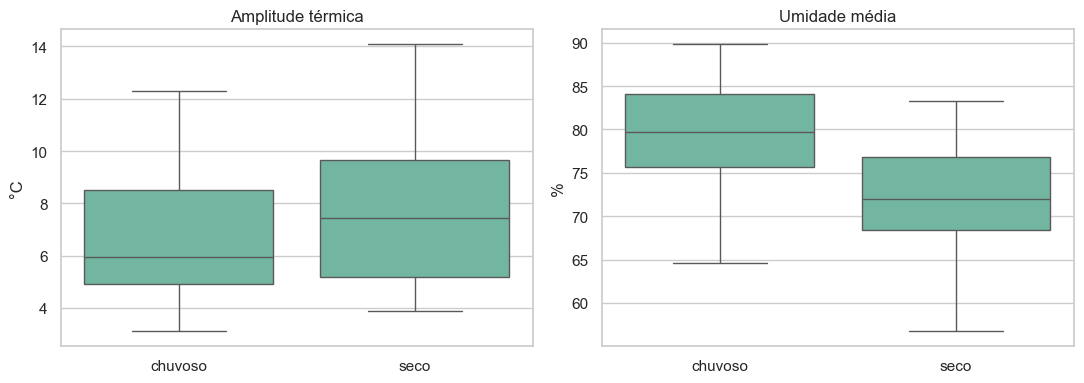

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=diario, x="categoria_chuva", y="amplitude_termica", ax=axes[0])
axes[0].set_title("Amplitude térmica")
axes[0].set_xlabel("")
axes[0].set_ylabel("°C")

sns.boxplot(data=diario, x="categoria_chuva", y="umidade_media", ax=axes[1])
axes[1].set_title("Umidade média")
axes[1].set_xlabel("")
axes[1].set_ylabel("%")

plt.tight_layout()
plt.show()

As caixas de `chuvoso` e `seco` ficam em alturas diferentes — sinal de que essas
colunas carregam informação útil para o modelo.

## 1.3 Separando `X` e `y`

Convenção do scikit-learn:

- **`X`** → a tabela de features (maiúsculo, porque é uma tabela);
- **`y`** → a coluna que queremos prever (minúsculo, porque é uma coluna só).

In [8]:
FEATURES_NUMERICAS = [
    "temp_media", "amplitude_termica", "umidade_media", "vento_medio", "choveu_ontem",
]
FEATURES_CATEGORICAS = ["regiao"]

X = diario[FEATURES_NUMERICAS + FEATURES_CATEGORICAS]
y = diario["categoria_chuva"]

print("X:", X.shape)
print("y:", y.shape)
X.head()

X: (150, 6)
y: (150,)


,temp_media,amplitude_termica,umidade_media,vento_medio,choveu_ontem,regiao
0,25.908333,3.1,86.104167,6.083333,1,Norte
1,27.587500,5.3,80.916667,4.937500,1,Norte
2,26.233333,4.4,86.166667,4.608333,0,Norte
3,25.795833,3.7,86.916667,4.100000,1,Norte
4,26.475000,5.0,85.166667,4.691667,1,Norte


## 1.4 Transformando colunas com `sklearn.preprocessing`

Os modelos do scikit-learn só trabalham com **números**. O módulo
`sklearn.preprocessing` traz várias ferramentas prontas para transformar as colunas.
Vamos explorar as duas mais usadas.

### `OneHotEncoder`: texto vira colunas de 0 e 1

A coluna `regiao` é texto. O `OneHotEncoder` cria **uma coluna por região**, com 1 se
a linha é daquela região e 0 caso contrário (é o mesmo que o `pd.get_dummies` do
pandas faz).

In [9]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
regioes_codificadas = encoder.fit_transform(X[["regiao"]])

pd.DataFrame(regioes_codificadas, columns=encoder.get_feature_names_out()).head()

,regiao_Nordeste,regiao_Norte,regiao_Sudeste,regiao_Sul
0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0


### `StandardScaler`: números na mesma escala

A umidade vai de ~60 a ~95, a amplitude térmica de ~2 a ~15 e o `choveu_ontem` é 0 ou
1. Alguns modelos se confundem com escalas tão diferentes. O `StandardScaler` deixa
todas as colunas com **média 0 e desvio padrão 1**:

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
numericas_padronizadas = scaler.fit_transform(X[FEATURES_NUMERICAS])

pd.DataFrame(numericas_padronizadas, columns=FEATURES_NUMERICAS).describe().round(2)

,temp_media,amplitude_termica,umidade_media,vento_medio,choveu_ontem
count,150.00,150.00,150.00,150.00,150.00
mean,-0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.57,-1.53,-2.85,-1.88,-1.37
25%,-0.71,-0.80,-0.74,-0.75,-1.37
50%,0.23,-0.30,0.05,-0.06,0.73
75%,0.70,0.74,0.73,0.53,0.73
max,2.52,2.63,1.86,2.83,0.73


Repare no padrão de uso, que se repete em **todas** as ferramentas de transformação:

| Método | O que faz |
|---|---|
| `.fit(dados)` | **aprende** com os dados (ex.: quais regiões existem, qual a média de cada coluna) |
| `.transform(dados)` | **aplica** a transformação usando o que aprendeu |
| `.fit_transform(dados)` | faz os dois de uma vez |

Esse detalhe vai ser importante na Etapa 2.

### `ColumnTransformer`: cada coluna com a sua transformação

Em vez de transformar cada grupo de colunas separadamente e depois colar tudo, o
`sklearn.compose.ColumnTransformer` junta tudo em uma única ferramenta: "nestas
colunas aplique isto, naquelas aplique aquilo".

In [11]:
from sklearn.compose import ColumnTransformer

preprocessador = ColumnTransformer([
    ("numericas", StandardScaler(), FEATURES_NUMERICAS),
    ("categoricas", OneHotEncoder(), FEATURES_CATEGORICAS),
])

preprocessador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

Ainda não aplicamos o `preprocessador` em nada — ele só ficou **configurado**. Vamos
usá-lo depois de separar treino e teste.

---

# Etapa 2 — Treino e teste

Para saber se o modelo realmente aprendeu, precisamos testá-lo em dias que ele **não
viu** durante o treino — como uma prova com questões diferentes das da lista de
exercícios. Se testássemos nos mesmos dias do treino, ele poderia simplesmente ter
"decorado" as respostas.

## 2.1 `train_test_split`, do `sklearn.model_selection`

In [12]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.25,    # 25% dos dias ficam guardados para o teste
    random_state=42,   # "semente": o sorteio dá sempre o mesmo resultado
    stratify=y,        # mantém a mesma proporção de chuvoso/seco nas duas partes
)

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)

Treino: (112, 6) | Teste: (38, 6)


A função devolve **quatro** resultados de uma vez, que guardamos em quatro variáveis
**na ordem**: features de treino, features de teste, respostas de treino, respostas
de teste.

O argumento `stratify=y` garante que a proporção de dias chuvosos seja parecida no
treino e no teste. Sem ele, com tão poucos dados, o sorteio poderia colocar quase
todos os dias secos de um lado só. Conferindo:

In [13]:
pd.DataFrame({
    "treino": y_treino.value_counts(normalize=True),
    "teste": y_teste.value_counts(normalize=True),
}).round(2)

,treino,teste
categoria_chuva,,
chuvoso,0.64,0.63
seco,0.36,0.37


## 2.2 Aplicando o pré-processamento: `fit` só no treino

Lembra do `.fit()` e `.transform()`? Agora usamos assim:

- **`fit_transform` no treino** → o pré-processador aprende as médias, desvios e
  regiões **só com os dias de treino**, e já transforma;
- **`transform` no teste** → aplica o que aprendeu no treino, sem aprender nada novo.

Por quê? Os dias de teste fazem o papel do "futuro", que o modelo não deveria
conhecer. Se o `fit` visse o teste, a prova estaria contaminada.

In [14]:
X_treino_prep = preprocessador.fit_transform(X_treino)
X_teste_prep = preprocessador.transform(X_teste)

nomes_features = preprocessador.get_feature_names_out()

pd.DataFrame(X_treino_prep, columns=nomes_features).head().round(2)

,numericas__temp_media,numericas__amplitude_termica,numericas__umidade_media,numericas__vento_medio,numericas__choveu_ontem,categoricas__regiao_Nordeste,categoricas__regiao_Norte,categoricas__regiao_Sudeste,categoricas__regiao_Sul
0,0.28,-1.47,1.21,-1.33,0.75,0.0,1.0,0.0,0.0
1,0.43,0.19,0.17,0.10,0.75,1.0,0.0,0.0,0.0
2,0.68,0.43,-0.19,0.40,0.75,1.0,0.0,0.0,0.0
3,-0.79,1.70,0.16,-0.51,0.75,0.0,0.0,1.0,0.0
4,0.75,-0.36,-0.13,1.53,0.75,1.0,0.0,0.0,0.0


---

# Etapa 3 — Modelo

## 3.1 O padrão de uso de qualquer modelo

Todo modelo do scikit-learn é usado do mesmo jeito, em três passos:

```python
modelo = NomeDoModelo(configurações)   # 1. criar
modelo.fit(X_treino, y_treino)         # 2. treinar (aprender com os exemplos)
modelo.predict(X_teste)                # 3. prever
```

## 3.2 Baseline: o "modelo" mais simples possível (`sklearn.dummy`)

Antes de qualquer modelo de verdade, criamos uma **régua**: um "modelo" que não olha
para nada e **sempre responde a categoria mais comum** (`chuvoso`). Se um modelo de
verdade não superar isso, ele não serve para nada.

In [15]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino_prep, y_treino)

previsoes_baseline = baseline.predict(X_teste_prep)
previsoes_baseline[:10]

array(['chuvoso', 'chuvoso', 'chuvoso', 'chuvoso', 'chuvoso', 'chuvoso',
       'chuvoso', 'chuvoso', 'chuvoso', 'chuvoso'], dtype='<U7')

## 3.3 Árvore de decisão (`sklearn.tree`)

Uma árvore de decisão aprende uma sequência de perguntas de "sim ou não" — parecido
com um fluxograma. É ótima para começar porque **dá para ver** o que ela aprendeu.

In [16]:
from sklearn.tree import DecisionTreeClassifier

arvore = DecisionTreeClassifier(max_depth=3, random_state=42)
arvore.fit(X_treino_prep, y_treino)

previsoes_arvore = arvore.predict(X_teste_prep)
previsoes_arvore[:10]

array(['chuvoso', 'chuvoso', 'seco', 'chuvoso', 'chuvoso', 'seco',
       'chuvoso', 'seco', 'chuvoso', 'chuvoso'], dtype=object)

O argumento `max_depth=3` limita a árvore a no máximo 3 perguntas em sequência — o que
a deixa pequena o suficiente para desenhar com a função `plot_tree`, do mesmo módulo:

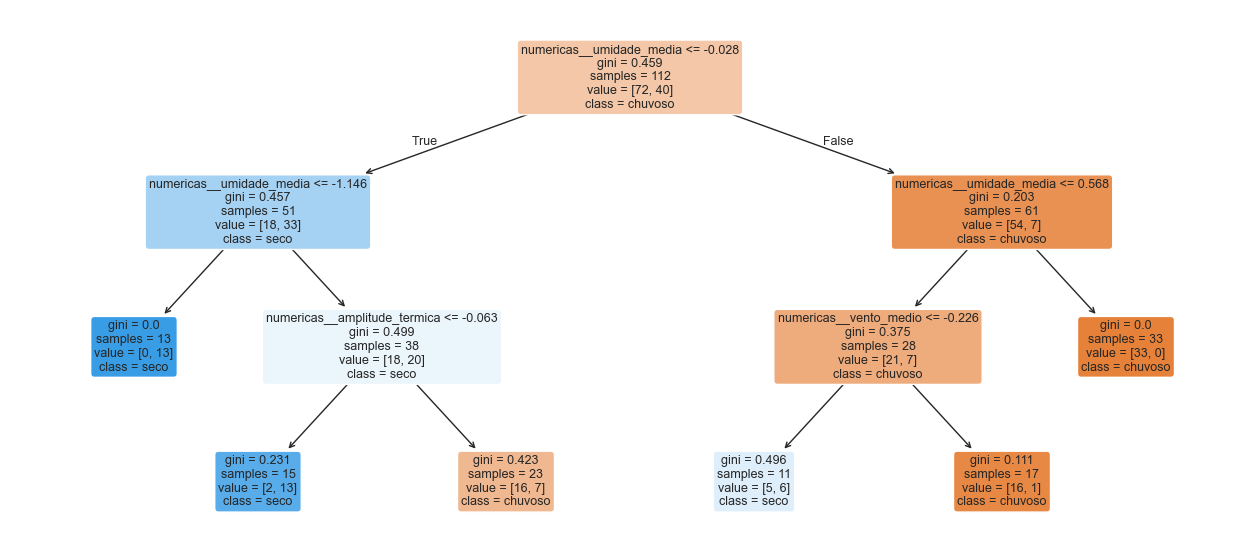

In [17]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    arvore,
    feature_names=nomes_features,
    class_names=arvore.classes_,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.show()

Como ler: comece pelo quadro do topo. Cada quadro faz uma pergunta (no nosso caso,
a primeira é sobre a `umidade_media`); se a resposta for **sim**, siga para a
esquerda, se for **não**, para a direita. Os quadros da última linha dão a resposta
final, e a cor indica a categoria (quanto mais forte, mais "certeza").

> Os valores nas perguntas estão **padronizados** pelo `StandardScaler` (média 0),
> por isso não aparecem em °C ou %.

## 3.4 Outros modelos: mesma receita

Por dentro, cada modelo funciona de um jeito completamente diferente. Por fora, todos
têm `.fit()` e `.predict()`. Isso permite testar vários modelos com um **dicionário**
e um **`for`**:

| Modelo | Módulo | Ideia em uma frase |
|---|---|---|
| `LogisticRegression` | `sklearn.linear_model` | combina as features com "pesos" e calcula uma probabilidade |
| `DecisionTreeClassifier` | `sklearn.tree` | um fluxograma de perguntas de sim ou não |
| `RandomForestClassifier` | `sklearn.ensemble` | várias árvores diferentes "votam" na resposta |

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

modelos = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=4, random_state=42),
}

previsoes = {}

for nome, modelo in modelos.items():
    modelo.fit(X_treino_prep, y_treino)
    previsoes[nome] = modelo.predict(X_teste_prep)

# Uma tabela com a resposta real e a de cada modelo, para os primeiros dias de teste
pd.DataFrame(previsoes).assign(real=y_teste.values).head(10)

,Baseline,Regressão Logística,Árvore de Decisão,Random Forest,real
0,chuvoso,chuvoso,chuvoso,chuvoso,chuvoso
1,chuvoso,chuvoso,chuvoso,chuvoso,chuvoso
2,chuvoso,seco,seco,seco,seco
3,chuvoso,seco,chuvoso,chuvoso,seco
4,chuvoso,chuvoso,chuvoso,seco,seco
5,chuvoso,seco,seco,seco,seco
6,chuvoso,chuvoso,chuvoso,chuvoso,chuvoso
7,chuvoso,chuvoso,seco,chuvoso,seco
8,chuvoso,chuvoso,chuvoso,chuvoso,chuvoso
9,chuvoso,chuvoso,chuvoso,chuvoso,chuvoso


## 3.5 Probabilidades com `predict_proba`

Além da resposta final, os modelos de classificação conseguem dizer **o quanto têm
certeza**, com o `.predict_proba()`. É a diferença entre dizer "vai chover" e "70% de
chance de chuva".

In [19]:
modelo_rl = modelos["Regressão Logística"]

probabilidades = modelo_rl.predict_proba(X_teste_prep)

pd.DataFrame(probabilidades, columns=modelo_rl.classes_).round(2).assign(
    previsto=modelo_rl.predict(X_teste_prep),
    real=y_teste.values,
).head(10)

,chuvoso,seco,previsto,real
0,0.64,0.36,chuvoso,chuvoso
1,0.69,0.31,chuvoso,chuvoso
2,0.25,0.75,seco,seco
3,0.42,0.58,seco,seco
4,0.57,0.43,chuvoso,seco
5,0.20,0.80,seco,seco
6,0.97,0.03,chuvoso,chuvoso
7,0.79,0.21,chuvoso,seco
8,0.88,0.12,chuvoso,chuvoso
9,0.96,0.04,chuvoso,chuvoso


O `.predict()` simplesmente escolhe a categoria com a maior probabilidade.

---

# Etapa 4 — Avaliação (`sklearn.metrics`)

## 4.1 Acurácia: quantos % o modelo acertou?

A métrica mais intuitiva: de todos os dias de teste, em quantos o modelo acertou?
Dá para calcular na mão com pandas — e com a função pronta do scikit-learn:

In [20]:
acertos_na_mao = (previsoes["Árvore de Decisão"] == y_teste).mean()
print(f"Acurácia calculada com pandas: {acertos_na_mao:.1%}")

Acurácia calculada com pandas: 65.8%


In [21]:
from sklearn.metrics import accuracy_score

acuracias = {
    nome: accuracy_score(y_teste, previsto)
    for nome, previsto in previsoes.items()
}

pd.Series(acuracias).sort_values(ascending=False).map("{:.1%}".format)

Regressão Logística    73.7%
Random Forest          68.4%
Árvore de Decisão      65.8%
Baseline               63.2%
dtype: object

⚠️ **Olhe o baseline.** Sem olhar para nenhuma informação, só respondendo sempre
"chuvoso", ele já acerta cerca de 63% dos dias — porque quase 2/3 dos dias **foram**
chuvosos. Por isso uma acurácia sozinha engana: os 66% da árvore de decisão parecem
razoáveis, mas são quase o mesmo que "chutar". O que importa é o quanto o modelo
**supera o baseline** — e aqui quem se destaca é a Regressão Logística.

> 💡 Os resultados são modestos, e tudo bem: treinamos com apenas **112 dias** e
> poucas features. Com mais dados (mais meses, mais cidades) e features melhores, os
> modelos tendem a melhorar bastante.

## 4.2 `classification_report`: um resumo por categoria

O `classification_report` resume, para **cada categoria**, duas perguntas:

- **precision** (precisão): dos dias que o modelo disse que eram `seco`, quantos eram
  mesmo?
- **recall** (revocação): dos dias que **eram** `seco`, quantos o modelo encontrou?

In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_teste, previsoes["Regressão Logística"]))

              precision    recall  f1-score   support

     chuvoso       0.79      0.79      0.79        24
        seco       0.64      0.64      0.64        14

    accuracy                           0.74        38
   macro avg       0.72      0.72      0.72        38
weighted avg       0.74      0.74      0.74        38



In [25]:
# O baseline nunca prevê "seco", então precisão e recall dessa categoria ficam zerados
print(classification_report(y_teste, previsoes["Baseline"], zero_division=0))

              precision    recall  f1-score   support

     chuvoso       0.63      1.00      0.77        24
        seco       0.00      0.00      0.00        14

    accuracy                           0.63        38
   macro avg       0.32      0.50      0.39        38
weighted avg       0.40      0.63      0.49        38



## 4.3 Quais features o modelo mais usou?

Modelos baseados em árvores guardam, depois do `.fit()`, o atributo
`feature_importances_`: quanto cada feature ajudou nas decisões (a soma dá 1).

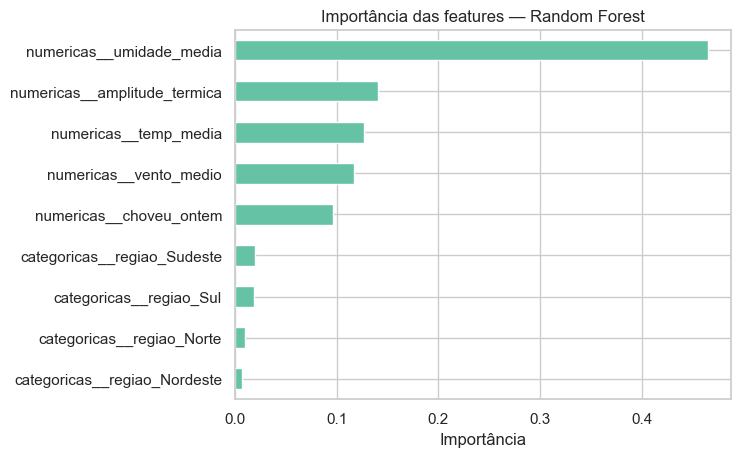

In [26]:
floresta = modelos["Random Forest"]

importancias = pd.Series(floresta.feature_importances_, index=nomes_features).sort_values()

ax = importancias.plot.barh()
ax.set_title("Importância das features — Random Forest")
ax.set_xlabel("Importância")
plt.show()

A umidade é, de longe, a feature mais usada — faz sentido. Em segundo lugar vem a
`amplitude_termica`, uma das features que **nós criamos** na Etapa 1 com uma linha de
pandas. Esse é o poder da engenharia de features: muitas vezes ela faz mais
diferença do que trocar de modelo.

---

# Resumo

| Etapa | O que fizemos | Ferramentas |
|---|---|---|
| **1. Engenharia de features** | criamos colunas novas, evitamos a "cola" e transformamos tudo em números | pandas (`shift`, `groupby`), `OneHotEncoder`, `StandardScaler`, `ColumnTransformer` |
| **2. Treino e teste** | separamos 75% / 25%, mantendo a proporção das categorias; `fit` só no treino | `train_test_split(..., stratify=y)`, `.fit_transform()` / `.transform()` |
| **3. Modelo** | criamos uma régua e testamos 3 modelos com a mesma receita | `DummyClassifier`, `LogisticRegression`, `DecisionTreeClassifier`, `RandomForestClassifier`, `.fit()`, `.predict()`, `.predict_proba()`, `plot_tree` |
| **4. Avaliação** | comparamos com o baseline e vimos onde cada modelo erra | `accuracy_score`, `confusion_matrix`, `ConfusionMatrixDisplay`, `classification_report`, `feature_importances_` |

**Os dois padrões que valem para o pacote inteiro:**

- Ferramentas de transformação: `.fit()` → `.transform()`
- Modelos: `.fit()` → `.predict()`

> 📚 Na disciplina de machine learning vocês vão ver o que acontece **dentro** desses
> modelos, como escolher as configurações e como avaliar com mais cuidado. A
> documentação oficial do pacote é excelente e cheia de exemplos:
> [scikit-learn.org](https://scikit-learn.org/stable/user_guide.html).